# KNN Regression — King County House Prices

Complete workflow: preprocessing, date handling, normalization, different K values, best K selection, MAE, MSE, RMSE, R², Actual vs Predicted graph, and Prediction Error graph.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Load dataset
df = pd.read_csv("KC_House_Data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (21613, 20)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,7700000,6,8.00,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
1,20140611T000000,7062500,5,4.50,10040,37325,2.0,1,2,3,11,7680,2360,1940,2001,98004,47.6500,-122.214,3930,25449
2,20140919T000000,6885000,6,7.75,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
3,20140804T000000,5570000,5,5.75,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345
4,20150413T000000,5350000,5,5.00,8000,23985,2.0,0,4,3,12,6720,1280,2009,0,98004,47.6232,-122.220,4600,21750


In [3]:
# Data quality check
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           21613 non-null  str    
 1   price          21613 non-null  int64  
 2   bedrooms       21613 non-null  int64  
 3   bathrooms      21613 non-null  float64
 4   sqft_living    21613 non-null  int64  
 5   sqft_lot       21613 non-null  int64  
 6   floors         21613 non-null  float64
 7   waterfront     21613 non-null  int64  
 8   view           21613 non-null  int64  
 9   condition      21613 non-null  int64  
 10  grade          21613 non-null  int64  
 11  sqft_above     21613 non-null  int64  
 12  sqft_basement  21613 non-null  int64  
 13  yr_built       21613 non-null  int64  
 14  yr_renovated   21613 non-null  int64  
 15  zipcode        21613 non-null  int64  
 16  lat            21613 non-null  float64
 17  long           21613 non-null  float64
 18  sqft_living15  21

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Duplicate Rows: 0


In [4]:
# Remove duplicates
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (21613, 20)


In [5]:
# Date handling
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["sale_year"] = df["date"].dt.year
df["sale_month"] = df["date"].dt.month
df["sale_day"] = df["date"].dt.day
df = df.drop("date", axis=1)

display(df[["sale_year", "sale_month", "sale_day"]].head())

,sale_year,sale_month,sale_day
0,2014,10,13
1,2014,6,11
2,2014,9,19
3,2014,8,4
4,2015,4,13


In [6]:
# Remove ID column
if "id" in df.columns:
    df = df.drop("id", axis=1)

# Target and features
y = df["price"]
X = df.drop("price", axis=1)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (21613, 21)
y Shape: (21613,)


In [7]:
# Zipcode is categorical, so one-hot encode it
if "zipcode" in X.columns:
    X["zipcode"] = X["zipcode"].astype(str)
    X = pd.get_dummies(X, columns=["zipcode"], drop_first=True)

print("Features after encoding:", X.shape)
print("Missing values:", X.isnull().sum().sum())

Features after encoding: (21613, 89)
Missing values: 0


In [8]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (17290, 89)
Testing data: (4323, 89)


In [9]:
# Normalize features
# Fit scaler only on training data to prevent data leakage
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature normalization completed.")

Feature normalization completed.


In [10]:
# Test different K values
k_values = [1, 3, 5, 7, 9, 11, 15, 20]

mae_scores = []
mse_scores = []
rmse_scores = []
r2_scores = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k, weights="uniform")
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    mae_scores.append(mae)
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    print(f"K={k:2d} | MAE={mae:,.2f} | RMSE={rmse:,.2f} | R²={r2:.4f}")

K= 1 | MAE=99,761.39 | RMSE=175,088.05 | R²=0.7464
K= 3 | MAE=83,550.51 | RMSE=150,280.70 | R²=0.8132
K= 5 | MAE=80,522.26 | RMSE=143,577.44 | R²=0.8295
K= 7 | MAE=81,379.95 | RMSE=145,245.91 | R²=0.8255
K= 9 | MAE=82,364.77 | RMSE=148,937.37 | R²=0.8165
K=11 | MAE=82,465.17 | RMSE=149,331.82 | R²=0.8155
K=15 | MAE=83,545.12 | RMSE=152,026.89 | R²=0.8088
K=20 | MAE=85,000.91 | RMSE=156,206.54 | R²=0.7982


In [11]:
# K comparison table
k_results = pd.DataFrame({
    "K": k_values,
    "MAE": mae_scores,
    "MSE": mse_scores,
    "RMSE": rmse_scores,
    "R2": r2_scores
})

display(k_results)

,K,MAE,MSE,RMSE,R2
0,1,99761.390701,3.065582e+10,175088.048630,0.746418
1,3,83550.508443,2.258429e+10,150280.703312,0.813185
2,5,80522.256674,2.061448e+10,143577.437344,0.829479
3,7,81379.947127,2.109637e+10,145245.906269,0.825493
4,9,82364.774179,2.218234e+10,148937.372842,0.816510
5,11,82465.166909,2.229999e+10,149331.823628,0.815537
6,15,83545.123525,2.311217e+10,152026.885551,0.808818
7,20,85000.912306,2.440048e+10,156206.537736,0.798162


In [12]:
# Select best K using the lowest RMSE
best_index = np.argmin(rmse_scores)
best_k = k_values[best_index]

print("Best K:", best_k)
print(f"Best RMSE: {rmse_scores[best_index]:,.2f}")

Best K: 5
Best RMSE: 143,577.44


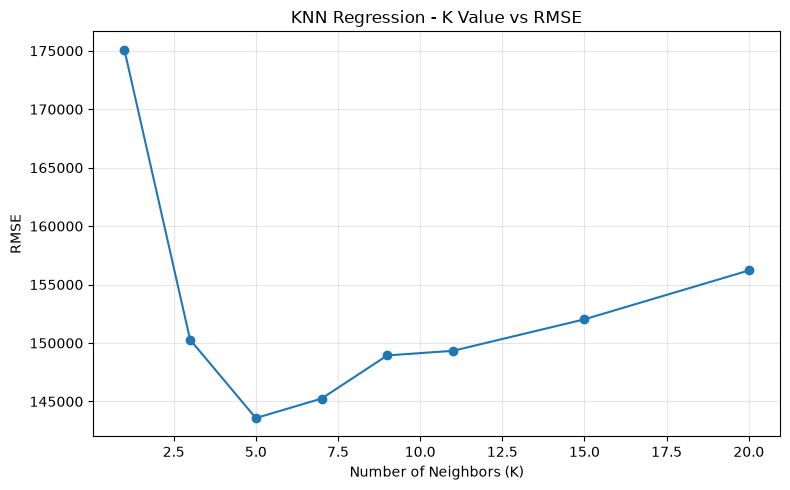

In [13]:
# K vs RMSE graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, rmse_scores, marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("RMSE")
plt.title("KNN Regression - K Value vs RMSE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Train final KNN model
final_model = KNeighborsRegressor(
    n_neighbors=best_k,
    weights="uniform"
)

final_model.fit(X_train_scaled, y_train)
y_pred = final_model.predict(X_test_scaled)

print("Final model trained successfully.")

Final model trained successfully.


In [15]:
# Final evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=" * 45)
print("FINAL KNN REGRESSION PERFORMANCE")
print("=" * 45)
print(f"Best K       : {best_k}")
print(f"MAE          : {mae:,.2f}")
print(f"MSE          : {mse:,.2f}")
print(f"RMSE         : {rmse:,.2f}")
print(f"R²           : {r2:.4f}")
print(f"R² Percentage: {r2 * 100:.2f}%")

FINAL KNN REGRESSION PERFORMANCE
Best K       : 5
MAE          : 80,522.26
MSE          : 20,614,480,514.25
RMSE         : 143,577.44
R²           : 0.8295
R² Percentage: 82.95%


In [16]:
# Actual vs Predicted table
results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

results["Prediction_Error"] = (
    results["Actual_Price"] - results["Predicted_Price"]
)

display(results.head(20))

,Actual_Price,Predicted_Price,Prediction_Error
0,1325000,970600.0,354400.0
1,813000,896600.0,-83600.0
2,718000,571400.0,146600.0
3,321000,292500.0,28500.0
4,230000,300690.0,-70690.0
5,1095000,1195500.0,-100500.0
6,260000,341900.0,-81900.0
7,248500,198400.0,50100.0
8,225000,181000.0,44000.0
9,568000,464600.0,103400.0


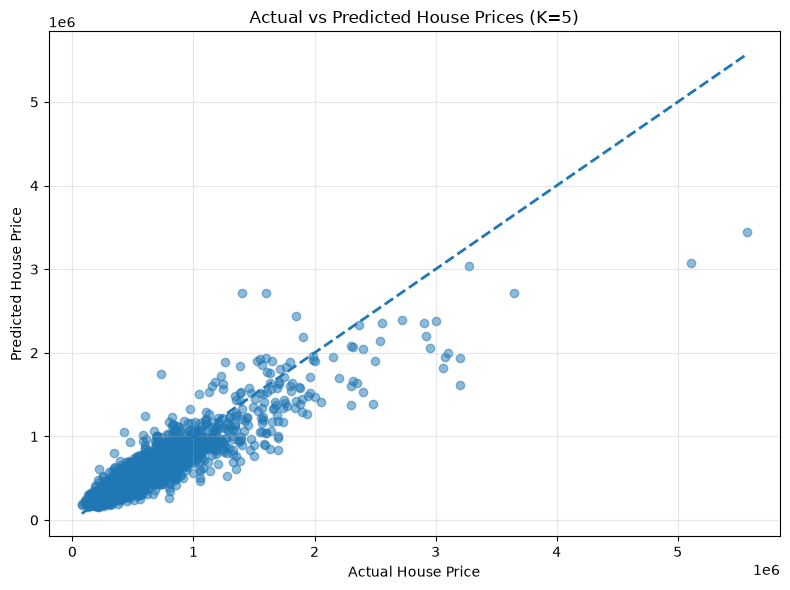

In [17]:
# Actual vs Predicted graph
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title(f"Actual vs Predicted House Prices (K={best_k})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

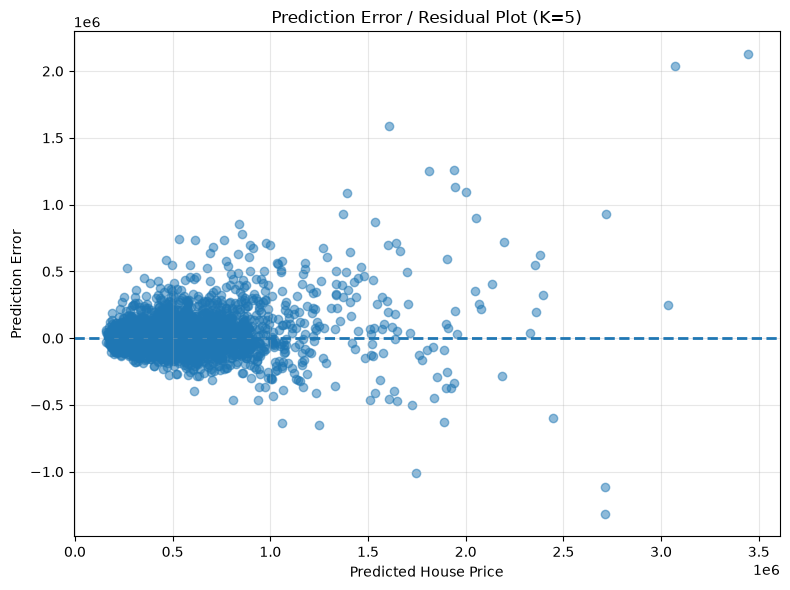

In [18]:
# Prediction Error / Residual graph
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--", linewidth=2)

plt.xlabel("Predicted House Price")
plt.ylabel("Prediction Error")
plt.title(f"Prediction Error / Residual Plot (K={best_k})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

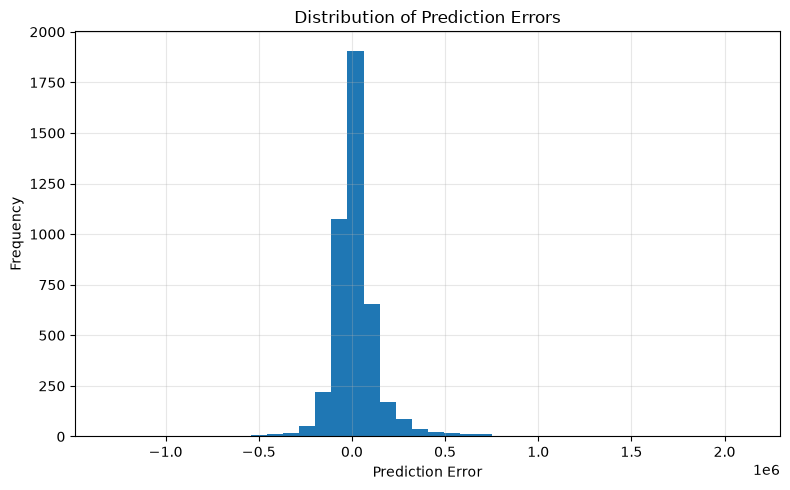

In [19]:
# Prediction error distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Save predictions
results.to_csv("KNN_house_price_predictions.csv", index=False)
print("Saved: KNN_house_price_predictions.csv")

Saved: KNN_house_price_predictions.csv


## Interpretation

- **MAE:** average absolute prediction error in original price units.
- **MSE:** mean squared prediction error.
- **RMSE:** error measure in the original price units; lower is better.
- **R²:** proportion of price variation explained by the model; higher is better.
- **Best K:** selected using the lowest RMSE.

**Why normalization?** KNN is distance-based, so features with larger numerical scales can dominate the distance calculation. StandardScaler puts the input features on comparable scales. The target `price` is not normalized.